# 04 - Context

**Purpose:** Clip geology/lithology (GSMB), soil type & thickness, and DS division boundaries to the AOI. Compute distance-to-river and distance-to-road rasters from OSM vector layers (`scipy.spatial.cKDTree` or `geopandas.sjoin_nearest`).

### Importing packages

In [1]:
import sys
import time
from pathlib import Path

import geopandas as gpd
import numpy as np
import pandas as pd
import rasterio
from rasterio.features import rasterize
from scipy.ndimage import distance_transform_edt
import matplotlib.pyplot as plt

sys.path.append("../src")
from landslide_lk import geo_utils

DATA_RAW = Path("../data/raw")
DATA_PROCESSED = Path("../data/processed")

### Load AOI and the terrain grid as a reference template

In [2]:
aoi = gpd.read_file(DATA_PROCESSED / "aoi.gpkg", layer="districts")
aoi_wgs84 = aoi.to_crs("EPSG:4326")
aoi_dissolved = gpd.read_file(DATA_PROCESSED / "aoi.gpkg", layer="dissolved")

template_path = DATA_PROCESSED / "slope.tif"
assert template_path.exists(), "slope.tif missing — run notebook 02 first"

with rasterio.open(template_path) as ref:
    ref_profile = ref.profile
    ref_transform = ref.transform
    ref_shape = ref.shape
    ref_crs = ref.crs

print("Reference grid:", ref_shape, ref_crs)

Reference grid: (5021, 4992) EPSG:32644


In [4]:
# DS division boundaries (admin3)
boundaries_path = DATA_RAW / "lka_admin_boundaries.gdb"  
admin3 = gpd.read_file(boundaries_path, layer="lka_admin3")
print(admin3.columns.tolist())

['adm3_name', 'adm3_name1', 'adm3_name2', 'adm3_name3', 'adm3_pcode', 'adm2_name', 'adm2_name1', 'adm2_name2', 'adm2_name3', 'adm2_pcode', 'adm1_name', 'adm1_name1', 'adm1_name2', 'adm1_name3', 'adm1_pcode', 'adm0_name', 'adm0_name1', 'adm0_name2', 'adm0_name3', 'adm0_pcode', 'valid_on', 'valid_to', 'area_sqkm', 'version', 'lang', 'lang1', 'lang2', 'lang3', 'center_lat', 'center_lon', 'geometry']


In [5]:
DISTRICT_COLUMN_L3 = "adm2_name"  # confirm from the printed columns above
TARGET_DISTRICTS = ["Kandy", "Kegalle", "Nuwara Eliya", "Ratnapura", "Badulla", "Kalutara"]

dsd_aoi = admin3[admin3[DISTRICT_COLUMN_L3].isin(TARGET_DISTRICTS)].copy()
print(f"{len(dsd_aoi)} DS divisions across {dsd_aoi[DISTRICT_COLUMN_L3].nunique()} districts")

dsd_aoi_utm = dsd_aoi.to_crs("EPSG:32644")
dsd_aoi_utm.to_file(DATA_PROCESSED / "aoi.gpkg", layer="dsd_divisions", driver="GPKG")

88 DS divisions across 6 districts


### geology & soil (GSMB)

In [ ]:
geology_path = DATA_RAW / "gsmb_geology.gpkg"  

if geology_path.exists():
    geology = gpd.read_file(geology_path).to_crs("EPSG:32644")
    print(f"GSMB geology loaded: {len(geology)} features")
else:
    print(
        "GSMB geology not yet available — requires direct institutional request. "
        "Logged as a data gap in docs/data_sources.md. "
        "Consider SoilGrids (ISRIC, free, 250m global) as an interim proxy for soil "
        "properties if GSMB access is delayed: https://soilgrids.org"
    )

GSMB geology not yet available — requires direct institutional request. Logged as a data gap in docs/data_sources.md. Consider SoilGrids (ISRIC, free, 250m global) as an interim proxy for soil properties if GSMB access is delayed: https://soilgrids.org


### OSM roads and rivers, one test query first

In [8]:
! pip install osmnx


[notice] A new release of pip is available: 26.0.1 -> 26.2
[notice] To update, run: C:\Users\PCC\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [9]:
import osmnx as ox

# Test: rivers/waterways for just one district first
test_district = aoi_wgs84[aoi_wgs84["adm2_name"] == "Kandy"].geometry.iloc[0]

test_rivers = ox.features_from_polygon(test_district, tags={"waterway": ["river", "stream"]})
print(f"Test: {len(test_rivers)} waterway features in Kandy")

Test: 328 waterway features in Kandy


In [ ]:
#full download, roads and rivers, per district then combined
all_rivers = []
all_roads = []

for _, row in aoi_wgs84.iterrows():
    district_name = row["adm2_name"]
    geom = row.geometry
    print(f"Fetching OSM data for {district_name}...")
    try:
        rivers = ox.features_from_polygon(geom, tags={"waterway": ["river", "stream"]})
        rivers["district"] = district_name
        all_rivers.append(rivers)
    except Exception as e:
        print(f"  rivers failed for {district_name}: {e}")

    try:
        roads = ox.features_from_polygon(geom, tags={"highway": True})
        roads["district"] = district_name
        all_roads.append(roads)
    except Exception as e:
        print(f"  roads failed for {district_name}: {e}")

    time.sleep(1) 

rivers_gdf = pd.concat(all_rivers, ignore_index=True)
roads_gdf = pd.concat(all_roads, ignore_index=True)

print(f"Total: {len(rivers_gdf)} river features, {len(roads_gdf)} road features")

rivers_gdf.to_crs("EPSG:32644").to_file(DATA_PROCESSED / "rivers.gpkg", driver="GPKG")
roads_gdf.to_crs("EPSG:32644").to_file(DATA_PROCESSED / "roads.gpkg", driver="GPKG")

Fetching OSM data for Kalutara...
Fetching OSM data for Kandy...
Fetching OSM data for Nuwara Eliya...
Fetching OSM data for Badulla...
  rivers failed for Badulla: ('Connection aborted.', ConnectionResetError(10054, 'An existing connection was forcibly closed by the remote host', None, 10054, None))


KeyboardInterrupt: 

In [11]:
import time

def fetch_osm_with_retry(polygon, tags, retries=3, base_wait=5):
    """Fetch OSM features for one polygon, retrying on connection errors."""
    for attempt in range(retries):
        try:
            return ox.features_from_polygon(polygon, tags=tags)
        except Exception as e:
            wait = base_wait * (attempt + 1)
            print(f"    attempt {attempt+1} failed ({e}); retrying in {wait}s...")
            time.sleep(wait)
    raise RuntimeError(f"Failed after {retries} attempts")

osm_checkpoint_dir = DATA_PROCESSED / "osm_checkpoints"
osm_checkpoint_dir.mkdir(exist_ok=True)

for _, row in aoi_wgs84.iterrows():
    district_name = row["adm2_name"]
    geom = row.geometry

    rivers_path = osm_checkpoint_dir / f"rivers_{district_name}.gpkg"
    roads_path = osm_checkpoint_dir / f"roads_{district_name}.gpkg"

    if rivers_path.exists() and roads_path.exists():
        print(f"Skipping {district_name} — already fetched")
        continue

    print(f"Fetching OSM data for {district_name}...")

    if not rivers_path.exists():
        try:
            rivers = fetch_osm_with_retry(geom, {"waterway": ["river", "stream"]})
            rivers["district"] = district_name
            rivers.to_file(rivers_path, driver="GPKG")
            print(f"  rivers: {len(rivers)} features saved")
        except Exception as e:
            print(f"  rivers FAILED for {district_name}: {e}")

    if not roads_path.exists():
        try:
            roads = fetch_osm_with_retry(geom, {"highway": True})
            roads["district"] = district_name
            roads.to_file(roads_path, driver="GPKG")
            print(f"  roads: {len(roads)} features saved")
        except Exception as e:
            print(f"  roads FAILED for {district_name}: {e}")

    time.sleep(2)

Fetching OSM data for Kalutara...
  rivers: 486 features saved
  roads FAILED for Kalutara: Error adding field 'FIXME' to layer
Fetching OSM data for Kandy...
  rivers: 328 features saved
  roads: 11466 features saved
Fetching OSM data for Nuwara Eliya...
  rivers: 363 features saved
  roads FAILED for Nuwara Eliya: Error adding field 'FIXME' to layer
Fetching OSM data for Badulla...
  rivers: 308 features saved
  roads FAILED for Badulla: Error adding field 'FIXME' to layer
Fetching OSM data for Ratnapura...
  rivers: 474 features saved
  roads FAILED for Ratnapura: Error adding field 'fixme' to layer
Fetching OSM data for Kegalle...
  rivers: 175 features saved
  roads FAILED for Kegalle: Error adding field 'FIXME' to layer


In [12]:
# switch to GeoParquet instead of GPKG — Parquet doesn't have this case-insensitivity restriction
def clean_and_save_roads(roads_gdf, district_name, out_dir):
    # Keep only what's actually needed — drops the problematic tag columns entirely
    keep_cols = ["geometry", "highway"]
    available = [c for c in keep_cols if c in roads_gdf.columns]
    cleaned = roads_gdf[available].copy()
    cleaned["district"] = district_name

    out_path = out_dir / f"roads_{district_name}.parquet"
    cleaned.to_parquet(out_path)
    return out_path, len(cleaned)

In [13]:
# Re-running for failed districts
failed_districts = ["Kalutara", "Nuwara Eliya", "Badulla", "Ratnapura", "Kegalle"]

for district_name in failed_districts:
    row = aoi_wgs84[aoi_wgs84["adm2_name"] == district_name].iloc[0]
    geom = row.geometry

    roads_path = osm_checkpoint_dir / f"roads_{district_name}.parquet"
    if roads_path.exists():
        continue

    print(f"Re-fetching roads for {district_name}...")
    try:
        roads = fetch_osm_with_retry(geom, {"highway": True})
        path, n = clean_and_save_roads(roads, district_name, osm_checkpoint_dir)
        print(f"  roads: {n} features saved to {path.name}")
    except Exception as e:
        print(f"  roads FAILED again for {district_name}: {e}")
    time.sleep(2)

Re-fetching roads for Kalutara...
  roads: 23180 features saved to roads_Kalutara.parquet
Re-fetching roads for Nuwara Eliya...
  roads: 6838 features saved to roads_Nuwara Eliya.parquet
Re-fetching roads for Badulla...
  roads: 11657 features saved to roads_Badulla.parquet
Re-fetching roads for Ratnapura...
  roads: 12648 features saved to roads_Ratnapura.parquet
Re-fetching roads for Kegalle...
  roads: 4670 features saved to roads_Kegalle.parquet


In [14]:
# Fixing kandy roads
kandy_roads_old = osm_checkpoint_dir / "roads_Kandy.gpkg"
if kandy_roads_old.exists():
    kandy_roads = gpd.read_file(kandy_roads_old)
    clean_and_save_roads(kandy_roads, "Kandy", osm_checkpoint_dir)
    print("Kandy roads converted to parquet for consistency")

Kandy roads converted to parquet for consistency


In [15]:
#Combining roads to one file
road_files_parquet = sorted(osm_checkpoint_dir.glob("roads_*.parquet"))
roads_gdf = pd.concat([gpd.read_parquet(f) for f in road_files_parquet], ignore_index=True)

print(f"Total roads: {len(roads_gdf)} features across {roads_gdf['district'].nunique()} districts")
print(sorted(roads_gdf["district"].unique()))

roads_gdf.to_crs("EPSG:32644").to_parquet(DATA_PROCESSED / "roads.parquet")

Total roads: 70459 features across 6 districts
['Badulla', 'Kalutara', 'Kandy', 'Kegalle', 'Nuwara Eliya', 'Ratnapura']


In [17]:
print(sorted(osm_checkpoint_dir.glob("rivers_*.gpkg")))

[WindowsPath('../data/processed/osm_checkpoints/rivers_Badulla.gpkg'), WindowsPath('../data/processed/osm_checkpoints/rivers_Kalutara.gpkg'), WindowsPath('../data/processed/osm_checkpoints/rivers_Kandy.gpkg'), WindowsPath('../data/processed/osm_checkpoints/rivers_Kegalle.gpkg'), WindowsPath('../data/processed/osm_checkpoints/rivers_Nuwara Eliya.gpkg'), WindowsPath('../data/processed/osm_checkpoints/rivers_Ratnapura.gpkg')]


In [18]:
# Combining rivers
river_files = sorted(osm_checkpoint_dir.glob("rivers_*.gpkg"))
print(f"{len(river_files)} river checkpoint files found")

rivers_gdf = pd.concat([gpd.read_file(f) for f in river_files], ignore_index=True)
print(f"Combined: {len(rivers_gdf)} features across {rivers_gdf['district'].nunique()} districts")
print(sorted(rivers_gdf["district"].unique()))

rivers_gdf.to_crs("EPSG:32644").to_file(DATA_PROCESSED / "rivers.gpkg", driver="GPKG")
print("Saved:", (DATA_PROCESSED / "rivers.gpkg").exists())

6 river checkpoint files found
Combined: 2134 features across 6 districts
['Badulla', 'Kalutara', 'Kandy', 'Kegalle', 'Nuwara Eliya', 'Ratnapura']
Saved: True


###  rasterize & distance transform (RAM-safe, uses the terrain grid)

In [19]:
# Reload the combined files
rivers_gdf = gpd.read_file(DATA_PROCESSED / "rivers.gpkg")
roads_gdf = gpd.read_parquet(DATA_PROCESSED / "roads.parquet")

print(f"Rivers: {len(rivers_gdf)} features, districts: {sorted(rivers_gdf['district'].unique())}")
print(f"Roads: {len(roads_gdf)} features, districts: {sorted(roads_gdf['district'].unique())}")

Rivers: 2134 features, districts: ['Badulla', 'Kalutara', 'Kandy', 'Kegalle', 'Nuwara Eliya', 'Ratnapura']
Roads: 70459 features, districts: ['Badulla', 'Kalutara', 'Kandy', 'Kegalle', 'Nuwara Eliya', 'Ratnapura']


In [20]:
# Reload reference grid
template_path = DATA_PROCESSED / "slope.tif"
with rasterio.open(template_path) as ref:
    ref_profile = ref.profile
    ref_transform = ref.transform
    ref_shape = ref.shape
    ref_crs = ref.crs

print("Reference grid:", ref_shape, ref_crs)

Reference grid: (5021, 4992) EPSG:32644


In [21]:
# Distance transform
from rasterio.features import rasterize
from scipy.ndimage import distance_transform_edt

def compute_distance_raster(vector_gdf, ref_transform, ref_shape, ref_crs, pixel_size):
    vector_proj = vector_gdf.to_crs(ref_crs) if vector_gdf.crs != ref_crs else vector_gdf
    shapes = [(geom, 1) for geom in vector_proj.geometry if geom is not None]

    burned = rasterize(
        shapes, out_shape=ref_shape, transform=ref_transform, fill=0, dtype="uint8"
    )
    dist_pixels = distance_transform_edt(burned == 0)
    dist_meters = dist_pixels * pixel_size
    return dist_meters.astype("float32")

pixel_size = abs(ref_transform.a)
print("Pixel size (m):", pixel_size)

dist_to_river = compute_distance_raster(rivers_gdf, ref_transform, ref_shape, ref_crs, pixel_size)
dist_to_road = compute_distance_raster(roads_gdf, ref_transform, ref_shape, ref_crs, pixel_size)

print("Distance to river range:", dist_to_river.min(), "-", dist_to_river.max())
print("Distance to road range:", dist_to_road.min(), "-", dist_to_road.max())

Pixel size (m): 30.69771113627107
Distance to river range: 0.0 - 46552.52
Distance to road range: 0.0 - 51531.94


### save both as GeoTIFFs matching the terrain grid

In [22]:
def save_like_reference(arr, dst_path, ref_profile):
    profile = ref_profile.copy()
    profile.update(dtype="float32", compress="deflate")
    with rasterio.open(dst_path, "w", **profile) as dst:
        dst.write(arr, 1)

save_like_reference(dist_to_river, DATA_PROCESSED / "dist_to_river.tif", ref_profile)
save_like_reference(dist_to_road, DATA_PROCESSED / "dist_to_road.tif", ref_profile)

print("Distance rasters saved")

Distance rasters saved


### Verify and visualize (downsampled)

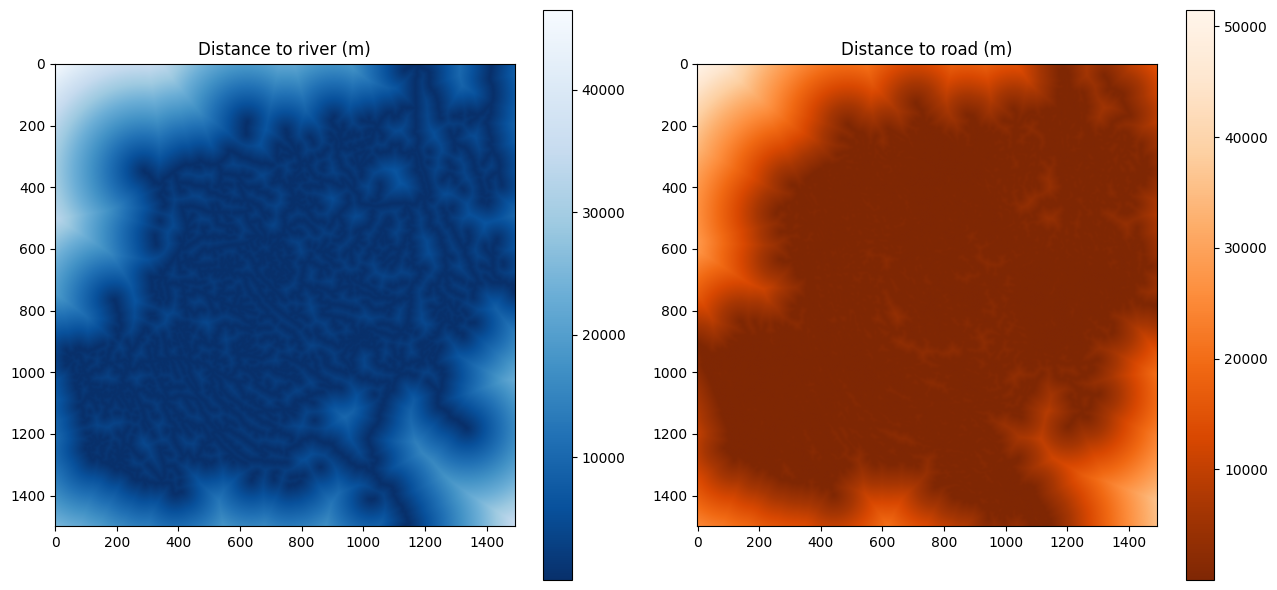

Distance to river: 9–46488 m
Distance to road: 0–51467 m


In [23]:
from rasterio.enums import Resampling

def read_downsampled(path, max_dim=1500):
    with rasterio.open(path) as src:
        scale = max(src.width, src.height) / max_dim
        out_shape = (src.count, int(src.height/scale), int(src.width/scale))
        return src.read(out_shape=out_shape, resampling=Resampling.bilinear)[0]

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
river_small = read_downsampled(DATA_PROCESSED / "dist_to_river.tif")
road_small = read_downsampled(DATA_PROCESSED / "dist_to_road.tif")

im0 = axes[0].imshow(river_small, cmap="Blues_r")
axes[0].set_title("Distance to river (m)")
plt.colorbar(im0, ax=axes[0])

im1 = axes[1].imshow(road_small, cmap="Oranges_r")
axes[1].set_title("Distance to road (m)")
plt.colorbar(im1, ax=axes[1])

plt.tight_layout()
plt.show()

print(f"Distance to river: {river_small.min():.0f}–{river_small.max():.0f} m")
print(f"Distance to road: {road_small.min():.0f}–{road_small.max():.0f} m")

1. Genuine geography (probably real): Sri Lanka's central highlands are where most rivers originate — it's the source/headwater region, so stream density is naturally higher there than toward the district edges. A radial "denser near center, sparser toward edges" pattern is plausible for real terrain.

2. A boundary edge-effect (likely partly artificial): distance_transform_edt only knows about rivers/roads inside your raster. A pixel sitting right at the edge of your AOI might genuinely be 200m from a real river but if that river happens to cross just outside your study area boundary, your data doesn't know it exists, and the algorithm reports a much larger distance than reality. This creates an artificial "glow" of inflated distance values hugging the edges of any clipped/bounded region — which is exactly the light halo you're seeing around the outside of the shape.

The bigger concern: 40–48km max is quite large

For Sri Lanka's central highlands specifically, dense terrain, historically well-settled, dense road network - a 48km maximum distance to the nearest road is surprisingly large.

### Fixing the boundaries and distances again

In [24]:
import numpy as np

max_idx = np.unravel_index(np.argmax(dist_to_road), dist_to_road.shape)
row, col = max_idx
x, y = rasterio.transform.xy(ref_transform, row, col)

# convert back to lat/lon for a map lookup
import pyproj
transformer = pyproj.Transformer.from_crs("EPSG:32644", "EPSG:4326", always_xy=True)
lon, lat = transformer.transform(x, y)
print(f"Max distance-to-road location: {lat:.5f}, {lon:.5f}")

# also check: is this pixel near the AOI's outer edge, or genuinely central/interior?
from shapely.geometry import Point
pt = Point(x, y)
dist_to_aoi_boundary = aoi_dissolved.to_crs("EPSG:32644").geometry.iloc[0].boundary.distance(pt)
print(f"Distance from this pixel to the AOI boundary: {dist_to_aoi_boundary:.0f} m")

Max distance-to-road location: 7.62166, 79.88312
Distance from this pixel to the AOI boundary: 52967 m


In [25]:
from shapely.geometry import Point

pt_wgs84 = Point(lon, lat)
is_inside = aoi_dissolved.geometry.iloc[0].contains(pt_wgs84)
print(f"Is this point actually inside the AOI polygon? {is_inside}")

Is this point actually inside the AOI polygon? False


### mask out anything outside the real AOI shape

In [29]:
with rasterio.open(DATA_PROCESSED / "slope.tif") as ref:
    slope_arr = ref.read(1)
    valid_mask = slope_arr != ref.nodata if ref.nodata is not None else ~np.isnan(slope_arr)

dist_to_river_masked = np.where(valid_mask, dist_to_river, np.nan)
dist_to_road_masked = np.where(valid_mask, dist_to_road, np.nan)

print("River — real range:", np.nanmin(dist_to_river_masked), "-", np.nanmax(dist_to_river_masked))
print("Road — real range:", np.nanmin(dist_to_road_masked), "-", np.nanmax(dist_to_road_masked))

River — real range: 0.0 - 12367.33
Road — real range: 0.0 - 5594.2314


In [30]:
max_idx = np.unravel_index(np.nanargmax(dist_to_road_masked), dist_to_road_masked.shape)
row, col = max_idx
x, y = rasterio.transform.xy(ref_transform, row, col)
lon2, lat2 = transformer.transform(x, y)
print(f"Real max distance-to-road location: {lat2:.5f}, {lon2:.5f}")
print(f"Value: {dist_to_road_masked[max_idx]:.0f} m")

Real max distance-to-road location: 7.48869, 81.11233
Value: 5594 m


In [31]:
save_like_reference(dist_to_river_masked.astype("float32"), DATA_PROCESSED / "dist_to_river.tif", ref_profile)
save_like_reference(dist_to_road_masked.astype("float32"), DATA_PROCESSED / "dist_to_road.tif", ref_profile)

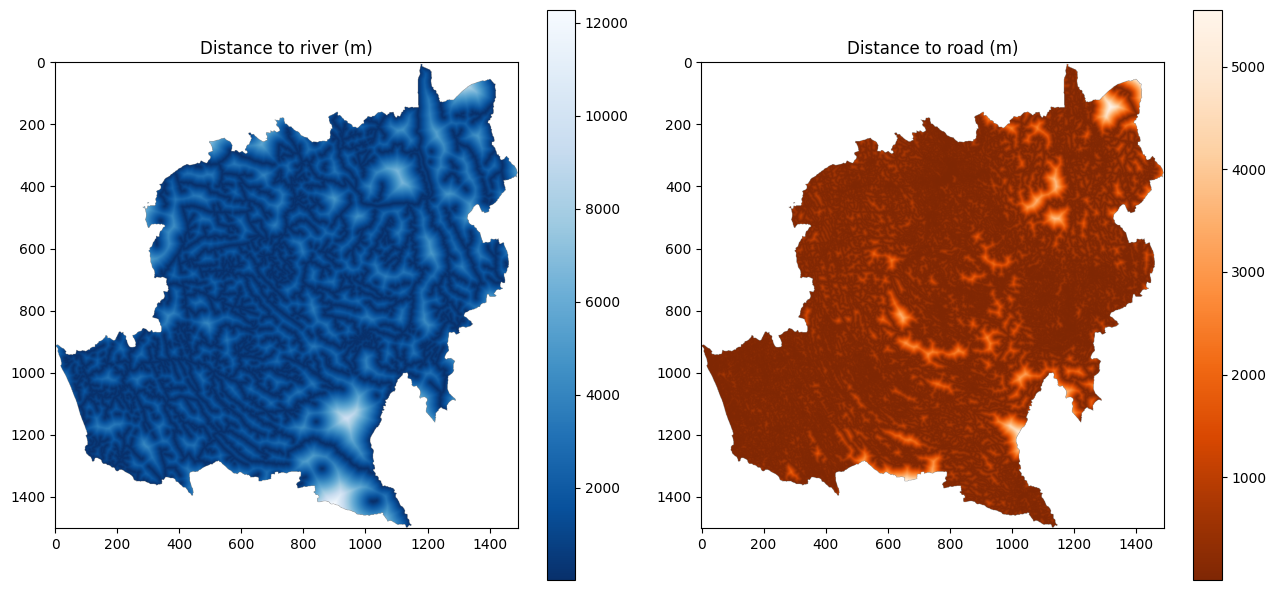

Distance to river: 0-12367 m
Distance to road: 0-5594 m


In [33]:
from rasterio.enums import Resampling

def read_downsampled(path, max_dim=1500):
    with rasterio.open(path) as src:
        scale = max(src.width, src.height) / max_dim
        out_shape = (src.count, int(src.height/scale), int(src.width/scale))
        return src.read(out_shape=out_shape, resampling=Resampling.bilinear)[0]

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
river_small = read_downsampled(DATA_PROCESSED / "dist_to_river.tif")
road_small = read_downsampled(DATA_PROCESSED / "dist_to_road.tif")

im0 = axes[0].imshow(river_small, cmap="Blues_r")
axes[0].set_title("Distance to river (m)")
plt.colorbar(im0, ax=axes[0])

im1 = axes[1].imshow(road_small, cmap="Oranges_r")
axes[1].set_title("Distance to road (m)")
plt.colorbar(im1, ax=axes[1])

plt.tight_layout()
plt.show()

print(f"Distance to river: {np.nanmin(dist_to_river_masked):.0f}-{np.nanmax(dist_to_river_masked):.0f} m")
print(f"Distance to road: {np.nanmin(dist_to_road_masked):.0f}-{np.nanmax(dist_to_road_masked):.0f} m")